In [2]:
!nvidia-smi

Wed Oct 28 05:42:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Before we start training, we need to gather and label images that will be used for training the object detection model. A good starting point for a proof-of-concept model is 200 images. The training images should have random objects in the image along with the desired objects, and should have a variety of backgrounds and lighting conditions.

There are a couple options for gathering images:


*   Build a custom dataset by taking your own pictures of the objects and labeling them (this typically results in the best performance)
*   Find a pre-made dataset from sources like [Roboflow Universe](), [Kaggle](), or [Google Images V7]()


If you want to build your own dataset, there are several tools available for labeling images. One good option is [Label Studio](https://labelstud.io/?utm_source=youtube&utm_medium=video&utm_campaign=edjeelectronics), a free and open-source labeling tool that has a simple workflow while providing capabilities for more advanced features. My YouTube video that walks through this notebook (link to be added soon) shows how to label images with Label Studio.

<p align=center>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/label-studio-example.PNG" height="380"><br>
<i>Example of a candy image labeled with Label Studio.</i>
</p>

If you used Label Studio to label and export the images, they'll be exported in a `project.zip` file that contains the following:

- An `images` folder containing the images
- A `labels` folder containing the labels in YOLO annotation format
- A `classes.txt` labelmap file that contains all the classes
- A `notes.json` file that contains info specific to Label Studio (this file can be ignored)

If you obtained your dataset from another source (like Roboflow Universe) or used another tool to label your dataset, make sure the files are organized in the same folder structure.

<p align=center>
<img src="https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/doc/zipped-data-example.png" height=""><br>
<i>Organize your data in the folders shown here. See my <a href="https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip">Candy Detection Dataset</a> for an example.</i>
</p>

Once you've got your dataset built, put into the file structure shown above, and zipped into `data.zip`, you're ready to move on to the next step.

# 2.&nbsp;Upload Image Dataset and Prepare Training Data

Next, we'll upload our dataset and prepare it for training with YOLO. We'll split the dataset into train and validation folders, and we'll automatically generate the configuration file for training the model.


**Copy from Google Drive**

You can also upload your images to your personal Google Drive, mount the drive on this Colab session, and copy them over to the Colab filesystem. This option works well if you want to upload the images beforehand so you don't have to wait for them to upload each time you restart this Colab. If you have more than 50MB worth of images, I recommend using this option.

First, upload the `data.zip` file to your Google Drive, and make note of the folder you uploaded them to. Replace `MyDrive/path/to/data.zip` with the path to your zip file. (For example, I uploaded the zip file to folder called "candy-data", so I would use `MyDrive/candydata/data.zip` for the path). Then, run the following block of code to mount your Google Drive to this Colab session and copy the folder to this filesystem.

In [5]:
from google.colab import drive
drive.mount('/content/gdrive')

!cp -r "/content/gdrive/MyDrive/candydata" /content/

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [6]:
import os

folder_path = "/content/candydata"

print("Folder exists:", os.path.exists(folder_path))
print("Contents:", os.listdir(folder_path)[:10])

Folder exists: True
Contents: ['notes.json', 'images', 'labels', 'classes.txt']


In [8]:
!cp "/content/gdrive/MyDrive/train_val_split.py" /content/

In [9]:
!python /content/train_val_split.py --datapath="/content/candydata" --train_pct=0.9

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 162
Number of annotation files: 162
Images moving to train: 145
Images moving to validation: 17


In [11]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


# 4.&nbsp;Configure Training


There's one last step before we can run training: we need to create the Ultralytics training configuration YAML file. This file specifies the location of your train and validation data, and it also defines the model's classes. An example configuration file model is available [here](https://github.com/ultralytics/ultralytics/blob/main/ultralytics/cfg/datasets/coco128.yaml).

Run the code block below to automatically generate a `data.yaml` configuration file. Make sure you have a labelmap file located at `custom_data/classes.txt`. If you used Label Studio or one of my pre-made datasets, it should already be present. If you assembled the dataset another way, you may have to manually create the `classes.txt` file (see [here](https://github.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/blob/main/doc/classes.txt) for an example of how it's formatted).

In [12]:

# Python function to automatically create data.yaml config file
# 1. Reads "classes.txt" file to get list of class names
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read classes.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return

  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0:
        continue
      classes.append(line.strip())

  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Write data in YAML format to data.yaml
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)

  print(f'Created config file at {path_to_data_yaml}')

  return

# Define path to classes.txt and run function
path_to_classes_txt = '/content/candydata/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

# Display the contents of data.yaml
print('\nFile contents:\n')
!cat /content/data.yaml


Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 11
names:
- MMs_peanut
- MMs_regular
- airheads
- gummy_worms
- milky_way
- nerds
- skittles
- snickers
- starbust
- three_musketeers
- twizzlers


# 5.&nbsp;Train Model

## 5.1 Training Parameters
Now that the data is organized and the config file is created, we're ready to start training! First, there are a few important parameters to decide on. Visit my article on [Training YOLO Models Locally](https://www.ejtech.io/learn/train-yolo-models) to learn more about these parameters and how to choose them.

**Model architecture & size (`model`):**

There are several YOLO11 models sizes available to train, including `yolo11n.pt`, `yolo11s.pt`, `yolo11m.pt`, `yolo11l.pt`, and `yolo11xl.pt`. Larger models run slower but have higher accuracy, while smaller models run faster but have lower accuracy. I made a brief YouTube video that compares performance of different YOLO models on a Raspberry Pi 5 and a laptop with a RTX 4050 GPU, [check it out here to get a sense of their speed accuracy](https://youtu.be/_WKS4E9SmkA). If you aren't sure which model size to use, `yolo11s.pt` is a good starting point.

You can also train YOLOv8 or YOLOv5 models by substituting `yolo11` for `yolov8` or `yolov5`.


**Number of epochs (`epochs`)**

In machine learning, one “epoch” is one single pass through the full training dataset. Setting the number of epochs dictates how long the model will train for. The best amount of epochs to use depends on the size of the dataset and the model architecture. If your dataset has less than 200 images, a good starting point is 60 epochs. If your dataset has more than 200 images, a good starting point is 40 epochs.


**Resolution (`imgsz`)**

Resolution has a large impact on the speed and accuracy of the model: a lower resolution model will have higher speed but less accuracy. YOLO models are typically trained and inferenced at a 640x640 resolution. However, if you want your model to run faster or know you will be working with low-resolution images, try using a lower resolution like 480x480.


Run the following code block to begin training. If you want to use a different model, number of epochs, or resolution, change `model`, `epochs`, or `imgsz`.


In [13]:
# 5.1 Define training parameters

# Model architecture and size
model = 'yolo11s.pt'

# Number of training epochs
epochs = 60

# Image resolution
imgsz = 640

# Batch size
batch = 16

print("Model:", model)
print("Epochs:", epochs)
print("Image size:", imgsz)
print("Batch size:", batch)

Model: yolo11s.pt
Epochs: 60
Image size: 640
Batch size: 16


In [14]:
!yolo detect train data=/content/data.yaml model={model} epochs={epochs} imgsz={imgsz} batch={batch}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None

The training algorithm will parse the images in the training and validation directories and then start training the model. At the end of each training epoch, the program runs the model on the validation dataset and reports the resulting mAP, precision, and recall. As training continues, the mAP should generally increase with each epoch. Training will end once it goes through the number of epochs specified by `epochs`.

> **NOTE:** Make sure to allow training to run to completion, because an optimizer runs at the end of training that strips out unneeded layers from the model.

The best trained model weights will be saved in `content/runs/detect/train/weights/best.pt`. Additional information about training is saved in the `content/runs/detect/train` folder, including a `results.png` file that shows how loss, precision, recall, and mAP progressed over each epoch.

#6.&nbsp;Test Model

The model has been trained; now it's time to test it! The commands below run the model on the images in the validation folder and then display the results for the first 10 images. This is a good way to confirm your model is working as expected. Click Play on the blocks below to see how your model performs.

In [15]:
!yolo detect predict model=/content/runs/detect/train/weights/best.pt source=/content/data/validation/images save=True

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs

image 1/17 /content/data/validation/images/0807ca73-candy_104.jpg: 480x640 1 MMs_regular, 2 airheadss, 1 gummy_worms, 1 snickers, 1 twizzlers, 17.5ms
image 2/17 /content/data/validation/images/5b8c27bf-candy_71.jpg: 480x640 1 MMs_regular, 1 airheads, 1 gummy_worms, 1 starbust, 1 three_musketeers, 17.7ms
image 3/17 /content/data/validation/images/8243fdc5-candy_13.jpg: 384x640 1 MMs_regular, 2 airheadss, 1 twizzlers, 49.6ms
image 4/17 /content/data/validation/images/888bff06-candy_93.jpg: 480x640 2 airheadss, 1 snickers, 1 three_musketeers, 18.3ms
image 5/17 /content/data/validation/images/8b14c1ad-candy_46.jpg: 384x640 1 airheads, 1 skittles, 2 starbusts, 16.9ms
image 6/17 /content/data/validation/images/993f5766-candy_73.jpg: 480x640 1 MMs_peanut, 2 airheadss, 1 gummy_worms, 2 nerdss, 1 skittles, 1 starbust, 1 three_mu

5b8c27bf-candy_71.jpg


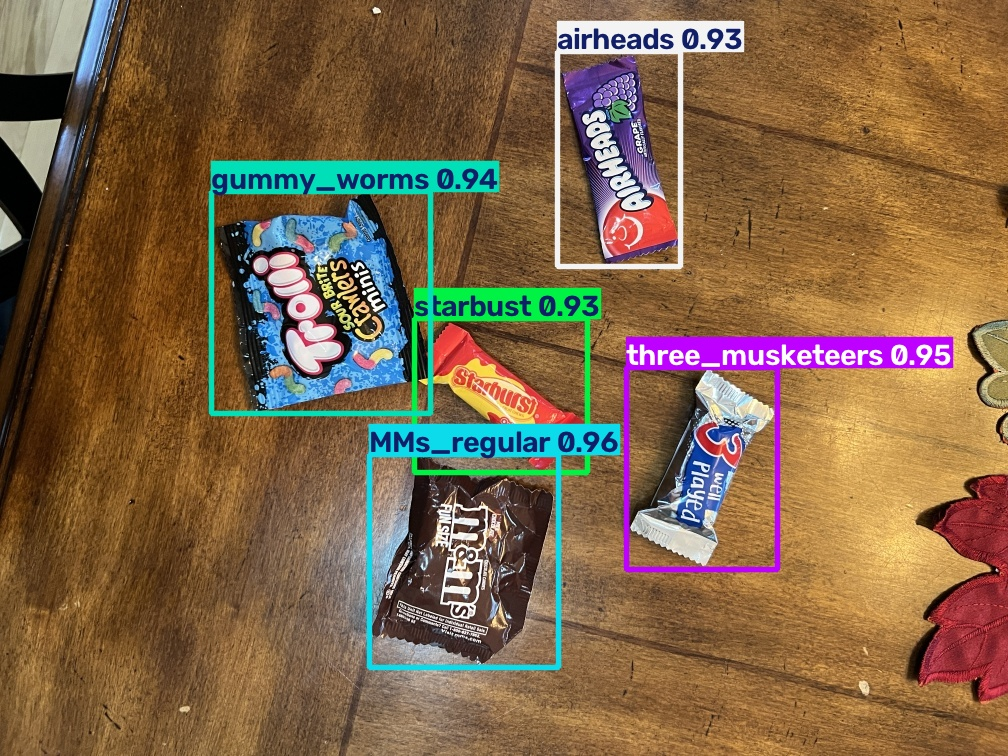

8243fdc5-candy_13.jpg


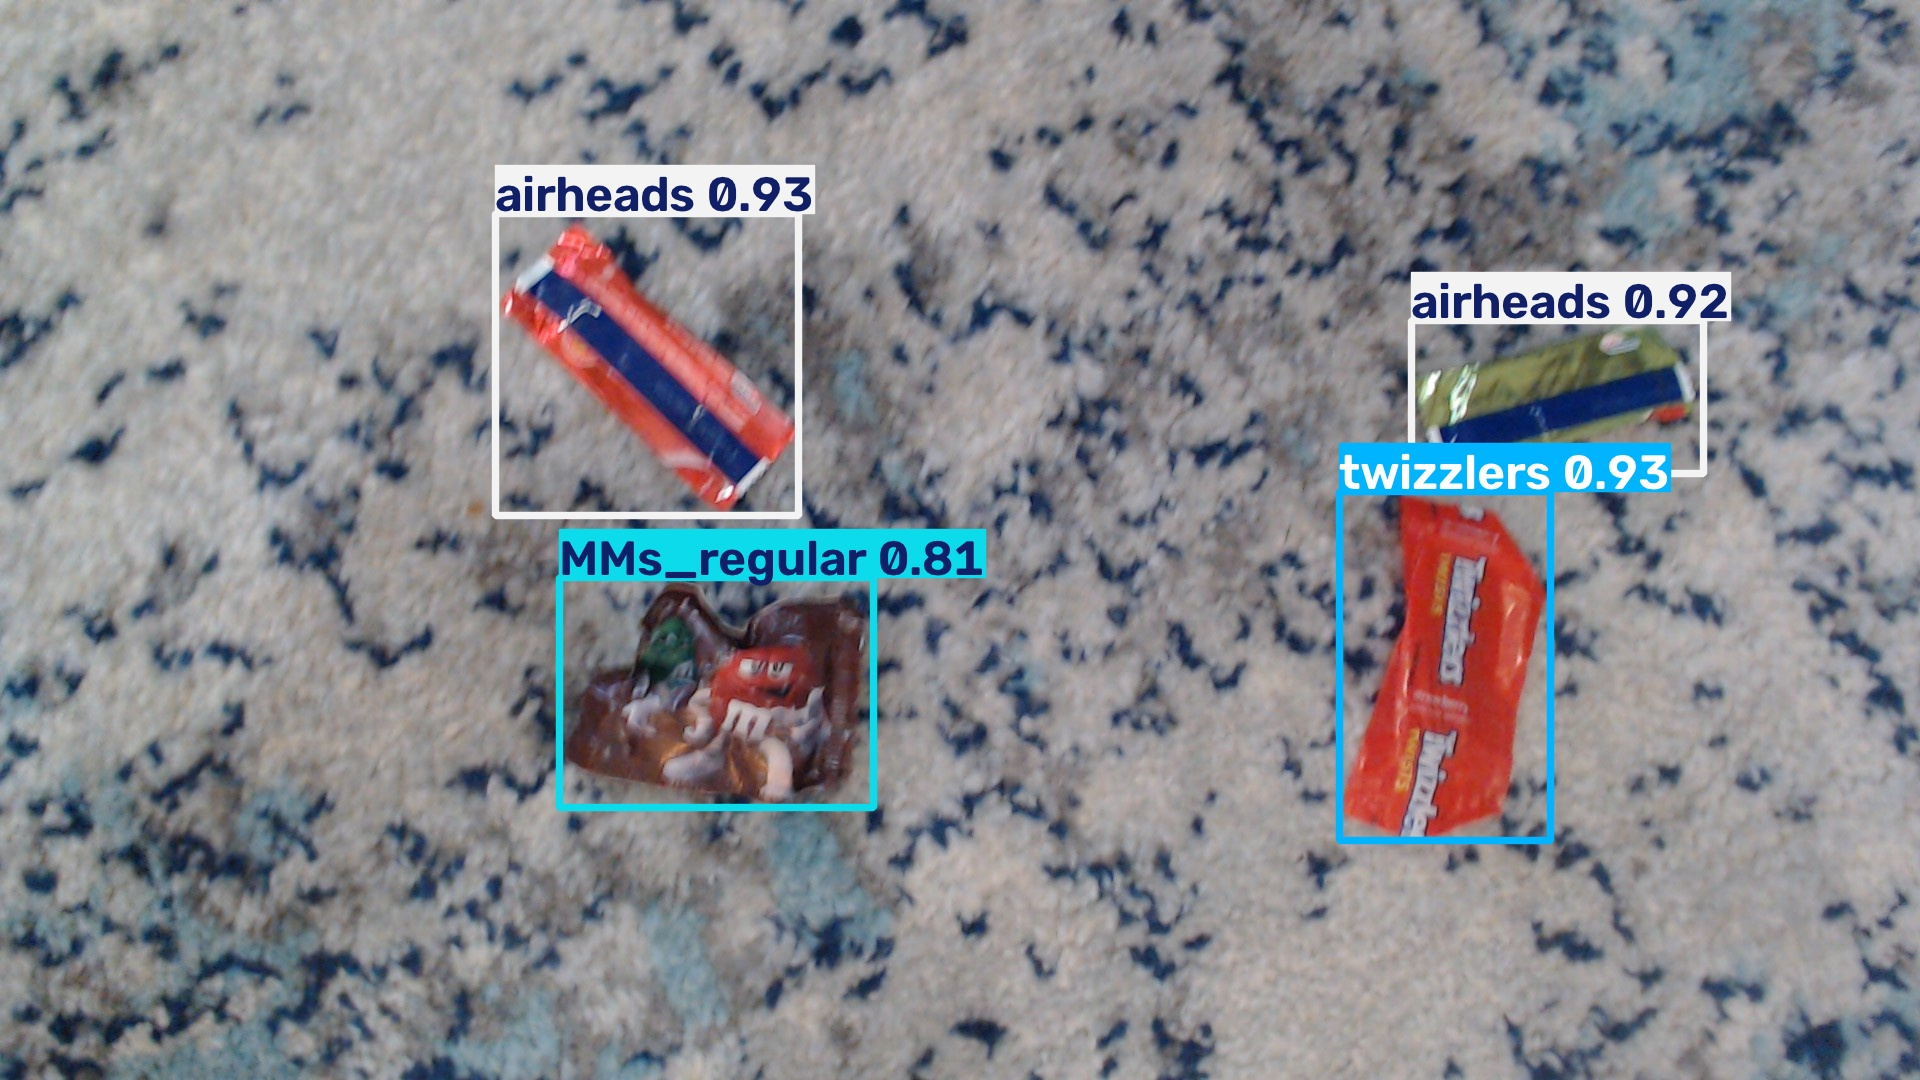

888bff06-candy_93.jpg


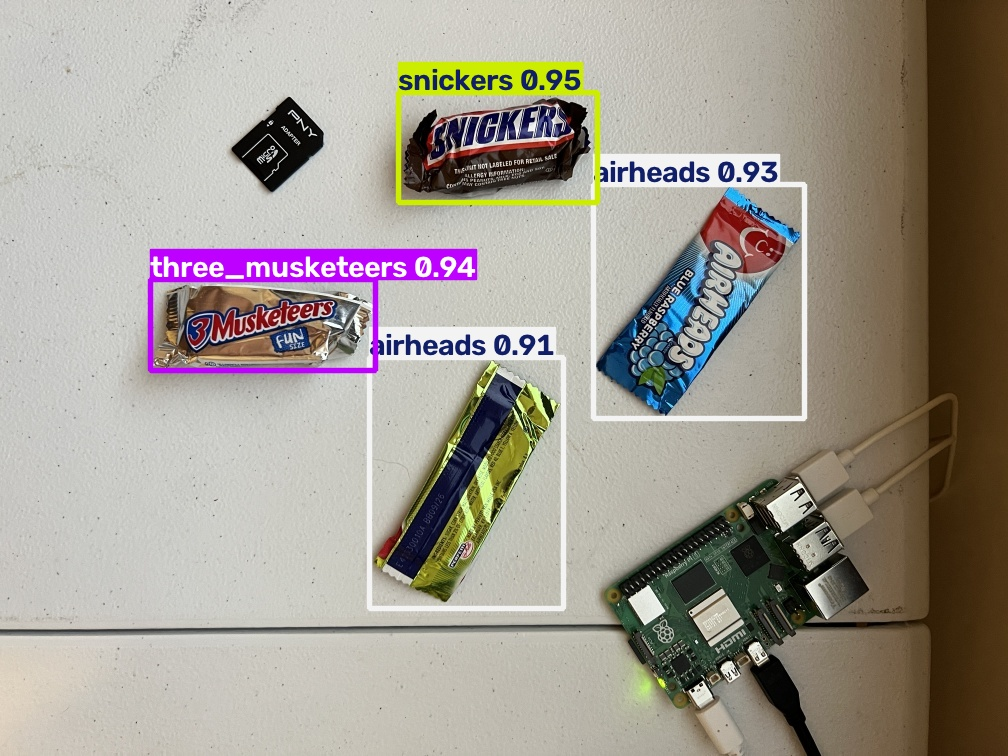

8b14c1ad-candy_46.jpg


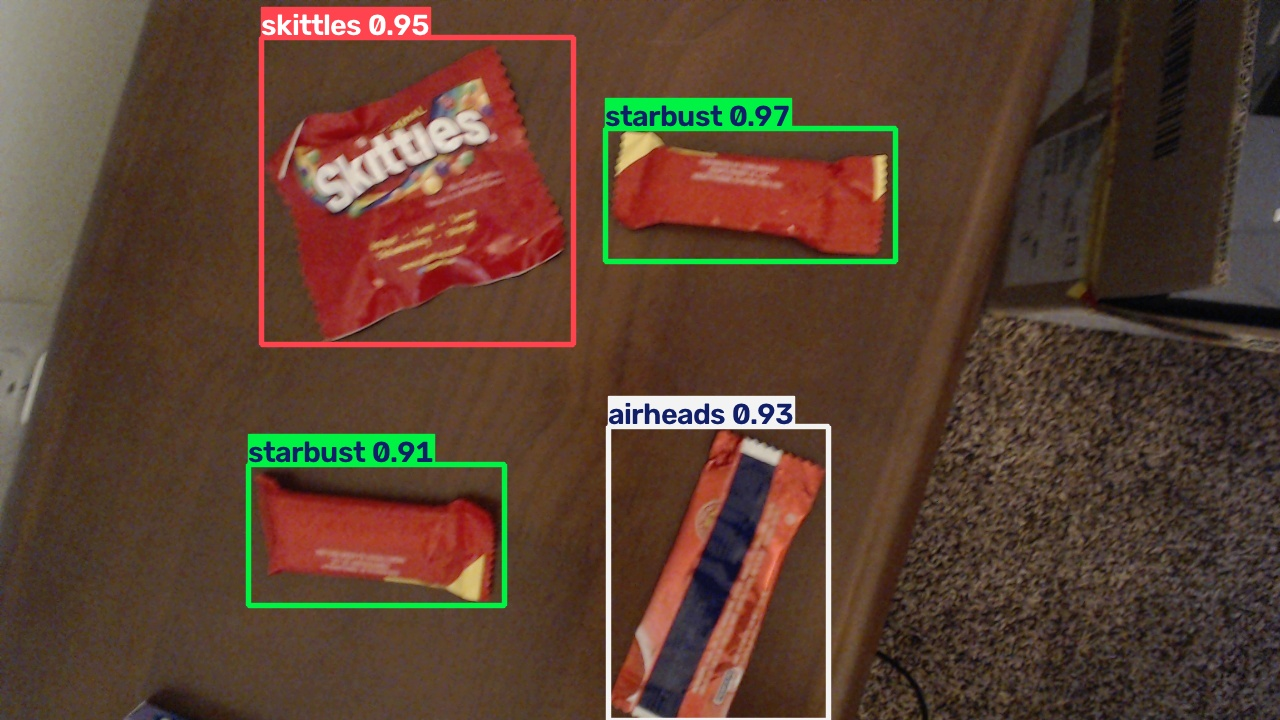

993f5766-candy_73.jpg


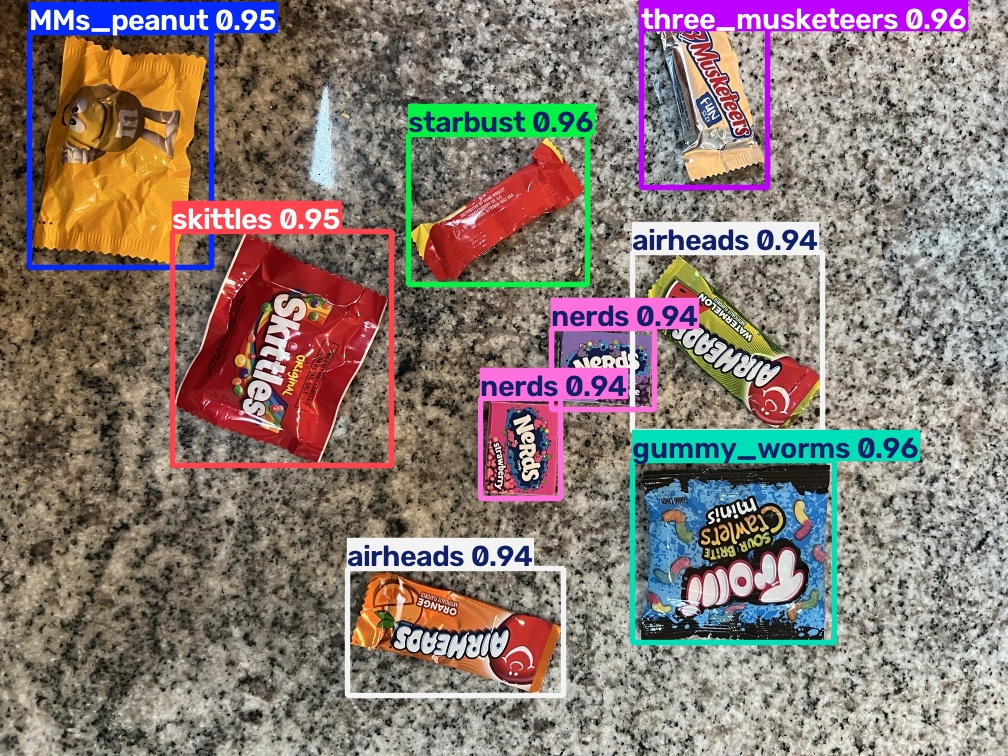

In [20]:
from IPython.display import display, Image
import glob
import os

images = sorted(glob.glob('/content/runs/detect/predict/*'))

for img in images[1:6]:
    print(os.path.basename(img))
    display(Image(filename=img))

In [21]:
!yolo detect val model=/content/runs/detect/train/weights/best.pt data=/content/data.yaml

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2561.4±711.3 MB/s, size: 316.3 KB)
val: Scanning /content/data/validation/labels.cache... 17 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.9it/s 1.1s
                   all         17         73      0.979      0.968      0.972      0.886
            MMs_peanut          4          4      0.975          1      0.995      0.877
           MMs_regular          7          8          1      0.997      0.995       0.92
              airheads          8         13      0.921          1       0.99      0.938
           gummy_worms          8          9      0.992          1      0.995      0.911
             milky_way          4          4   

## 7.1 Download YOLO Model

First, zip and download the trained model by running the code blocks below.

The code creates a folder named `my_model`, moves the model weights into it, and renames them from `best.pt` to `my_model.pt`. It also adds the training results in case you want to reference them later. It then zips the folder as `my_model.zip`.

In [23]:
# Step 1: Remove any previous package and ZIP file
!rm -rf /content/my_model
!rm -f /content/my_model.zip

# Step 2: Create a fresh folder
!mkdir -p /content/my_model

# Step 3: Copy the best trained model weights
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt

# Step 4: Copy training results, graphs, metrics, and checkpoints
!cp -r /content/runs/detect/train /content/my_model/

# Step 5: Copy validation evaluation results
!cp -r /content/runs/detect/val /content/my_model/

# Step 6: Copy prediction images with bounding boxes
!cp -r /content/runs/detect/predict /content/my_model/

# Step 7: Create a ZIP containing all the files
!cd /content && zip -r my_model.zip my_model

# Step 8: Display the ZIP file size
!ls -lh /content/my_model.zip

  adding: my_model/ (stored 0%)
  adding: my_model/predict/ (stored 0%)
  adding: my_model/predict/cfc53128-candy_117.jpg (deflated 0%)
  adding: my_model/predict/5b8c27bf-candy_71.jpg (deflated 0%)
  adding: my_model/predict/faab64dc-candy_37.jpg (deflated 0%)
  adding: my_model/predict/8243fdc5-candy_13.jpg (deflated 1%)
  adding: my_model/predict/c6f6d1e3-candy_91.jpg (deflated 0%)
  adding: my_model/predict/ac2edc49-candy_44.jpg (deflated 0%)
  adding: my_model/predict/a0fee6bc-candy_55.jpg (deflated 0%)
  adding: my_model/predict/c32d7e35-candy_119.jpg (deflated 0%)
  adding: my_model/predict/e7e53847-candy_113.jpg (deflated 0%)
  adding: my_model/predict/a37c7dfe-candy_47.jpg (deflated 0%)
  adding: my_model/predict/0807ca73-candy_104.jpg (deflated 0%)
  adding: my_model/predict/888bff06-candy_93.jpg (deflated 0%)
  adding: my_model/predict/b6d1ec80-candy_149.jpg (deflated 0%)
  adding: my_model/predict/8b14c1ad-candy_46.jpg (deflated 0%)
  adding: my_model/predict/b446c9db-candy

In [24]:
# Import the download utility
from google.colab import files

# Download the ZIP file to your computer
files.download('/content/my_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>